# 16a — LightGBM improvements

Notebook 16 tested LightGBM with almost no tuning: only the leaf count (15, 31 or 63) was searched, training used 350K sampled rows per five-year window, and there was no row bagging. A quick check also found that tree models can't easily rebuild **ratios** such as "prior-day auction volume ÷ 20-day median", while ridge effectively can, because ridge works on logged inputs.

This notebook adds one change at a time, so each step's effect can be read separately:

| Step | Candidate | Change vs previous step |
|---|---|---|
| A | `lgbm_58_control` | Notebook 16's `lgbm_residual_58_l2`, refit here on the same rows as B so A and B can be compared directly |
| B | `lgbm_61_ratios` | + 3 ratio features |
| C | `lgbm_61_ratios_large` | + about 3× more training rows (750K tune / 1M refit) |
| D | `lgbm_61_ratios_large_tuned` | + wider hyperparameter search (8 prespecified configurations, including row bagging) |
| E | `lgbm_61_ratios_large_linear` | linear trees (each leaf fits a small ridge model) instead of constant leaves |

The protocol is the same as Notebook 16: residual target relative to the 20-day median, five-year rolling windows, the previous year for validation and early stopping, 2022–2024 development years, and 2025 as confirmation only. A candidate must improve mean development log RMSE by at least 0.002, be no more than 0.002 worse in any development year, and pass a paired date-block log-MAE bootstrap.

**New features.** Every input is known by the end of day t−1, because the Notebook 05 rolling windows stop at the previous day:

- `ratio_lag1_med20` = ln((lag1 auction volume + 1) / (20-day median + 1))
- `ratio_avg5_med20` = ln((5-day average + 1) / (20-day median + 1))
- `ratio_lag1_med60` = ln((lag1 auction volume + 1) / (60-day median + 1))

In [1]:
import json
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

import challenger_utils as cu

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*eval_set.*deprecated.*")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

OUT = cu.output_dir("16a_lightgbm_improvements")
print(f"Project root: {cu.PROJECT_ROOT}")
print(f"Outputs: {OUT}")
print(f"LightGBM {lgb.__version__}; smoke mode: {cu.SMOKE}")
print(f"Features: base={len(cu.BASE_FEATURES)}, with ratios={len(cu.RATIO_SET)}")

Project root: /Users/alisapriyadarsini/Downloads/capstone/blackrock_workspace
Outputs: /Users/alisapriyadarsini/Downloads/capstone/blackrock_workspace/outputs/eda/16a_lightgbm_improvements
LightGBM 4.7.0; smoke mode: False
Features: base=58, with ratios=61


## Leakage check on the new ratio features

In [2]:
# The ratio inputs must come only from days before t. For five stocks, rebuild lag1, avg5,
# median20 and median60 straight from the raw CRSP + auction files, using windows that stop at
# the previous row, and confirm they match the panel. A zero gap means no same-day information.
DATA = cu.PROJECT_ROOT / "blackrock_data" / "stock_daily"
check = cu.sql(f"""
    WITH stocks AS (
        SELECT permno FROM read_parquet('{cu.PANEL}') GROUP BY permno ORDER BY count(*) DESC, permno LIMIT 5
    ), base AS (
        SELECT c.date, c.permno, a.auction_volume
        FROM read_parquet('{DATA}/crsp_daily/*/*.parquet', union_by_name=true) c
        LEFT JOIN read_parquet('{DATA}/auction_daily/*/*.parquet', union_by_name=true) a USING (date, permno)
        WHERE c.permno IN (SELECT permno FROM stocks)
    ), rebuilt AS (
        SELECT date, permno,
               lag(auction_volume) OVER (PARTITION BY permno ORDER BY date) AS lag1,
               avg(auction_volume) OVER (PARTITION BY permno ORDER BY date ROWS BETWEEN 5 PRECEDING AND 1 PRECEDING) AS avg5,
               median(auction_volume) OVER (PARTITION BY permno ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING) AS med20,
               median(auction_volume) OVER (PARTITION BY permno ORDER BY date ROWS BETWEEN 60 PRECEDING AND 1 PRECEDING) AS med60
        FROM base
    )
    SELECT count(*) AS stock_days_compared,
           max(abs(p.lag1_auction_volume - r.lag1)) AS max_gap_lag1,
           max(abs(p.avg5_auction_volume - r.avg5)) AS max_gap_avg5,
           max(abs(p.median20_auction_volume - r.med20)) AS max_gap_median20,
           max(abs(p.median60_auction_volume - r.med60)) AS max_gap_median60
    FROM rebuilt r JOIN read_parquet('{cu.PANEL}') p USING (date, permno)
""")
display(check)
assert (check.filter(like="max_gap").fillna(0).abs() < 1e-6).all(axis=None), "Ratio inputs do not match a t-1 rebuild"

,stock_days_compared,max_gap_lag1,max_gap_avg5,max_gap_median20,max_gap_median60
0,13830,0,0.0000,0.0000,0.0000


## Candidate definitions

In [3]:
N_JOBS = 6
CAP = 3000  # maximum trees; early stopping (patience 100) normally stops well before this

NB16_PARAMS = {  # Notebook 16 settings, except num_leaves, which is searched
    "objective": "regression", "learning_rate": 0.03, "min_child_samples": 500, "max_bin": 127,
    "colsample_bytree": 0.85, "reg_alpha": 0.1, "reg_lambda": 5.0,
}
LEAF_GRID = [{**NB16_PARAMS, "num_leaves": n} for n in (15, 31, 63)]

# D: eight prespecified configurations, fixed before seeing any results.
TUNED_GRID = [
    {"learning_rate": 0.05, "num_leaves": 63,  "min_child_samples": 300,  "subsample": 0.8, "colsample_bytree": 0.70, "reg_lambda": 5.0},
    {"learning_rate": 0.05, "num_leaves": 127, "min_child_samples": 500,  "subsample": 0.8, "colsample_bytree": 0.85, "reg_lambda": 10.0},
    {"learning_rate": 0.05, "num_leaves": 255, "min_child_samples": 1000, "subsample": 0.7, "colsample_bytree": 0.70, "reg_lambda": 20.0},
    {"learning_rate": 0.03, "num_leaves": 127, "min_child_samples": 200,  "subsample": 1.0, "colsample_bytree": 0.60, "reg_lambda": 5.0},
    {"learning_rate": 0.05, "num_leaves": 31,  "min_child_samples": 100,  "subsample": 0.8, "colsample_bytree": 0.85, "reg_lambda": 1.0},
    {"learning_rate": 0.03, "num_leaves": 255, "min_child_samples": 500,  "subsample": 0.8, "colsample_bytree": 0.85, "reg_lambda": 10.0},
    {"learning_rate": 0.05, "num_leaves": 127, "min_child_samples": 2000, "subsample": 0.9, "colsample_bytree": 0.60, "reg_lambda": 1.0},
    {"learning_rate": 0.03, "num_leaves": 63,  "min_child_samples": 1000, "subsample": 0.7, "colsample_bytree": 0.85, "reg_lambda": 20.0},
]
TUNED_GRID = [{"objective": "regression", "max_bin": 127, "reg_alpha": 0.1, "subsample_freq": 1, **c} for c in TUNED_GRID]

# E: linear trees. Each leaf fits a ridge regression on the leaf's rows (linear_lambda = ridge penalty).
LINEAR_GRID = [
    {**NB16_PARAMS, "learning_rate": 0.05, "num_leaves": 31, "linear_tree": True, "linear_lambda": 1.0},
    {**NB16_PARAMS, "learning_rate": 0.05, "num_leaves": 63, "linear_tree": True, "linear_lambda": 1.0},
]


def lgbm_fit(x, y, x_val, y_val, config, seed):
    model = lgb.LGBMRegressor(n_estimators=CAP, random_state=seed, n_jobs=N_JOBS, deterministic=True,
                              force_col_wise=True, verbosity=-1, **config)
    model.fit(x, y, eval_set=[(x_val, y_val)], eval_metric="rmse",
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model, int(model.best_iteration_)


def lgbm_refit(x, y, config, iterations, seed):
    model = lgb.LGBMRegressor(n_estimators=iterations, random_state=seed, n_jobs=N_JOBS, deterministic=True,
                              force_col_wise=True, verbosity=-1, **config)
    return model.fit(x, y)


def lgbm_importance(model):
    return model.booster_.feature_importance(importance_type="gain")


def candidate(name, tier, features, configs):
    if cu.SMOKE:
        configs = configs[:1]
    return {"name": name, "family": "LightGBM", "tier": tier, "features": features, "configs": configs,
            "fit": lgbm_fit, "refit": lgbm_refit, "importance": lgbm_importance}


CANDIDATES = [
    candidate("lgbm_58_control", "base", cu.BASE_FEATURES, LEAF_GRID),
    candidate("lgbm_61_ratios", "base", cu.RATIO_SET, LEAF_GRID),
    candidate("lgbm_61_ratios_large", "large", cu.RATIO_SET, LEAF_GRID),
    candidate("lgbm_61_ratios_large_tuned", "large", cu.RATIO_SET, TUNED_GRID),
    candidate("lgbm_61_ratios_large_linear", "large", cu.RATIO_SET, LINEAR_GRID),
]
NAMES = [c["name"] for c in CANDIDATES]
display(pd.DataFrame([{"candidate": c["name"], "tier": c["tier"], "features": len(c["features"]),
                       "configs searched": len(c["configs"])} for c in CANDIDATES]))
pd.DataFrame(TUNED_GRID).to_csv(OUT / "tuned_search_space.csv", index_label="config_id")

,candidate,tier,features,configs searched
0,lgbm_58_control,base,58,3
1,lgbm_61_ratios,base,61,3
2,lgbm_61_ratios_large,large,61,3
3,lgbm_61_ratios_large_tuned,large,61,8
4,lgbm_61_ratios_large_linear,large,61,2


## Rolling out-of-time run

This is the long step: about 1.5–2.5 hours on an 8 GB M2.

In [4]:
metrics, validation, importance = cu.run_experiment(CANDIDATES, OUT, tag="lgbm_improvements")
display(metrics.pivot_table(index="candidate", columns="test_year", values="rmse_log").loc[[cu.CHAMPION] + NAMES])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[    14s] 2022 tier=base rows={'tune': 250000, 'validation': 120000, 'refit': 350000}


[    79s]   lgbm_58_control: best config 0 (2272 iters, val rmse 0.5772)


[   171s]   lgbm_61_ratios: best config 0 (2030 iters, val rmse 0.5747)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (39 outputs left out)

[  3496s]   lgbm_61_ratios_large_tuned: best config 3 (519 iters, val rmse 0.4302)


[  3562s]   lgbm_61_ratios_large_linear: best config 1 (176 iters, val rmse 0.4310)


[  3578s] wrote 307,853 predictions for 2025


test_year,2022,2023,2024,2025
candidate,,,,
rolling5_residual_auction_calendar_liquidity,0.5338,0.4838,0.4460,0.4467
lgbm_58_control,0.5167,0.4613,0.4396,0.4350
lgbm_61_ratios,0.5137,0.4599,0.4367,0.4290
lgbm_61_ratios_large,0.5060,0.4559,0.4343,0.4236
lgbm_61_ratios_large_tuned,0.5025,0.4547,0.4335,0.4242
lgbm_61_ratios_large_linear,0.5322,0.4537,0.4368,0.4251


## Step-by-step effect of each change

In [5]:
annual = metrics.pivot_table(index="candidate", columns="test_year", values="rmse_log")
steps = [("B: + ratios", "lgbm_61_ratios", "lgbm_58_control"),
         ("C: + more data", "lgbm_61_ratios_large", "lgbm_61_ratios"),
         ("D: + wider tuning", "lgbm_61_ratios_large_tuned", "lgbm_61_ratios_large"),
         ("E: linear trees vs C", "lgbm_61_ratios_large_linear", "lgbm_61_ratios_large"),
         ("Overall: D vs control", "lgbm_61_ratios_large_tuned", "lgbm_58_control")]
step_table = pd.DataFrame([
    {"step": label, **{f"{y}": annual.loc[new, y] - annual.loc[old, y] for y in cu.TEST_YEARS},
     "mean_development_change": (annual.loc[new, cu.DEVELOPMENT_YEARS] - annual.loc[old, cu.DEVELOPMENT_YEARS]).mean()}
    for label, new, old in steps
])
step_table.to_csv(OUT / "step_effects.csv", index=False)
display(step_table)

,step,2022,2023,2024,2025,mean_development_change
0,B: + ratios,-0.0030,-0.0014,-0.0030,-0.0060,-0.0024
1,C: + more data,-0.0077,-0.0040,-0.0023,-0.0053,-0.0047
2,D: + wider tuning,-0.0035,-0.0012,-0.0008,0.0005,-0.0018
3,E: linear trees vs C,0.0262,-0.0022,0.0025,0.0015,0.0088
4,Overall: D vs control,-0.0142,-0.0066,-0.0061,-0.0108,-0.0090


## Replacement gate

Each candidate is judged against two references: the frozen ridge benchmark (the project rule) and the in-notebook LightGBM control (did the change help LightGBM itself?).

In [6]:
GLOB = str(OUT / "predictions" / "lgbm_improvements_predictions_*.parquet")
vs_ridge, boot_ridge = cu.decision_table(metrics, GLOB, cu.CHAMPION, NAMES)
vs_control, boot_control = cu.decision_table(metrics, GLOB, "lgbm_58_control", NAMES[1:])
pd.concat([vs_ridge, vs_control]).to_csv(OUT / "candidate_selection.csv", index=False)
pd.concat([boot_ridge.assign(reference=cu.CHAMPION), boot_control.assign(reference="lgbm_58_control")]).to_csv(
    OUT / "date_block_bootstrap.csv", index=False)
print("Against the frozen ridge benchmark")
display(vs_ridge)
print("Against the LightGBM control")
display(vs_control)

Against the frozen ridge benchmark


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,lgbm_58_control,rolling5_residual_auction_calendar_liquidity,0.4725,0.4350,0.3554,-0.0153,-0.0064,-0.0117,-0.0062,-0.0021,True,True,True,True
1,lgbm_61_ratios,rolling5_residual_auction_calendar_liquidity,0.4701,0.4290,0.3526,-0.0178,-0.0094,-0.0177,-0.0086,-0.0044,True,True,True,True
2,lgbm_61_ratios_large,rolling5_residual_auction_calendar_liquidity,0.4654,0.4236,0.3507,-0.0225,-0.0117,-0.0230,-0.0099,-0.0056,True,True,True,True
3,lgbm_61_ratios_large_tuned,rolling5_residual_auction_calendar_liquidity,0.4636,0.4242,0.3488,-0.0243,-0.0125,-0.0225,-0.0119,-0.0075,True,True,True,True
4,lgbm_61_ratios_large_linear,rolling5_residual_auction_calendar_liquidity,0.4742,0.4251,0.3634,-0.0136,-0.0016,-0.0215,0.0010,0.0065,True,True,False,False
5,rolling5_residual_auction_calendar_liquidity,rolling5_residual_auction_calendar_liquidity,0.4879,0.4467,0.3674,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


Against the LightGBM control


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,lgbm_61_ratios,lgbm_58_control,0.4701,0.4290,0.3526,-0.0024,-0.0014,-0.0060,-0.0024,-0.0018,True,True,True,True
1,lgbm_61_ratios_large,lgbm_58_control,0.4654,0.4236,0.3507,-0.0071,-0.0053,-0.0114,-0.0037,-0.0021,True,True,True,True
2,lgbm_61_ratios_large_tuned,lgbm_58_control,0.4636,0.4242,0.3488,-0.0090,-0.0061,-0.0108,-0.0057,-0.0044,True,True,True,True
3,lgbm_61_ratios_large_linear,lgbm_58_control,0.4742,0.4251,0.3634,0.0017,0.0154,-0.0099,0.0073,0.0106,False,False,False,False
4,lgbm_58_control,lgbm_58_control,0.4725,0.4350,0.3554,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


## Selected hyperparameters

In [7]:
chosen = validation.loc[validation.groupby(["test_year", "candidate"]).validation_rmse_log.idxmin()]
display(chosen[["test_year", "candidate", "config_id", "best_iteration", "validation_rmse_log", "config"]]
        .sort_values(["candidate", "test_year"]))

,test_year,candidate,config_id,best_iteration,validation_rmse_log,config
0,2022,lgbm_58_control,0,2272,0.5772,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."
19,2023,lgbm_58_control,0,2272,0.5099,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."
40,2024,lgbm_58_control,2,1089,0.4609,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."
59,2025,lgbm_58_control,2,1119,0.4389,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."
3,2022,lgbm_61_ratios,0,2030,0.5747,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."
22,2023,lgbm_61_ratios,0,2580,0.5086,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."
43,2024,lgbm_61_ratios,2,1066,0.4578,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."
62,2025,lgbm_61_ratios,2,770,0.4361,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."
7,2022,lgbm_61_ratios_large,1,1505,0.5691,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."
26,2023,lgbm_61_ratios_large,1,1559,0.5064,"{""colsample_bytree"": 0.85, ""learning_rate"": 0...."


## Where the gains come from

candidate                     frozen_prediction  lgbm_58_control  \
dimension   segment                                                
actual_tail lower_99pct                  0.4741           0.4618   
            top_1pct                     1.3191           1.1727   
event       month_end                    0.6866           0.6648   
            monthly_expiry               0.5441           0.5497   
            quarterly_expiry             0.8077           0.7779   
            regular                      0.4672           0.4515   
size        large                        0.4103           0.4007   
            mid                          0.4479           0.4355   
            small                        0.6058           0.5822   

candidate                     lgbm_61_ratios  lgbm_61_ratios_large  \
dimension   segment                                                  
actual_tail lower_99pct               0.4596                0.4557   
            top_1pct                  1.1577                1.1147   
event       month_end                 0.6622                0.6484   
            monthly_expiry            0.5466                0.5432   
            quarterly_expiry          0.7767                0.7640   
            regular                   0.4491                0.4450   
size        large                     0.3975                0.3944   
            mid                       0.4322                0.4286   
            small                     0.5810                0.5736   

candidate                     lgbm_61_ratios_large_linear  \
dimension   segment                                         
actual_tail lower_99pct                            0.4663   
            top_1pct                               1.0955   
event       month_end                              0.6470   
            monthly_expiry                         0.5427   
            quarterly_expiry                       0.7677   
            regular                                0.4565   
size        large                                  0.4096   
            mid                                    0.4395   
            small                                  0.5786   

candidate                     lgbm_61_ratios_large_tuned  
dimension   segment                                       
actual_tail lower_99pct                           0.4538  
            top_1pct                              1.1094  
event       month_end                             0.6479  
            monthly_expiry                        0.5402  
            quarterly_expiry                      0.7591  
            regular                               0.4431  
size        large                                 0.3926  
            mid                                   0.4268  
            small                                 0.5713

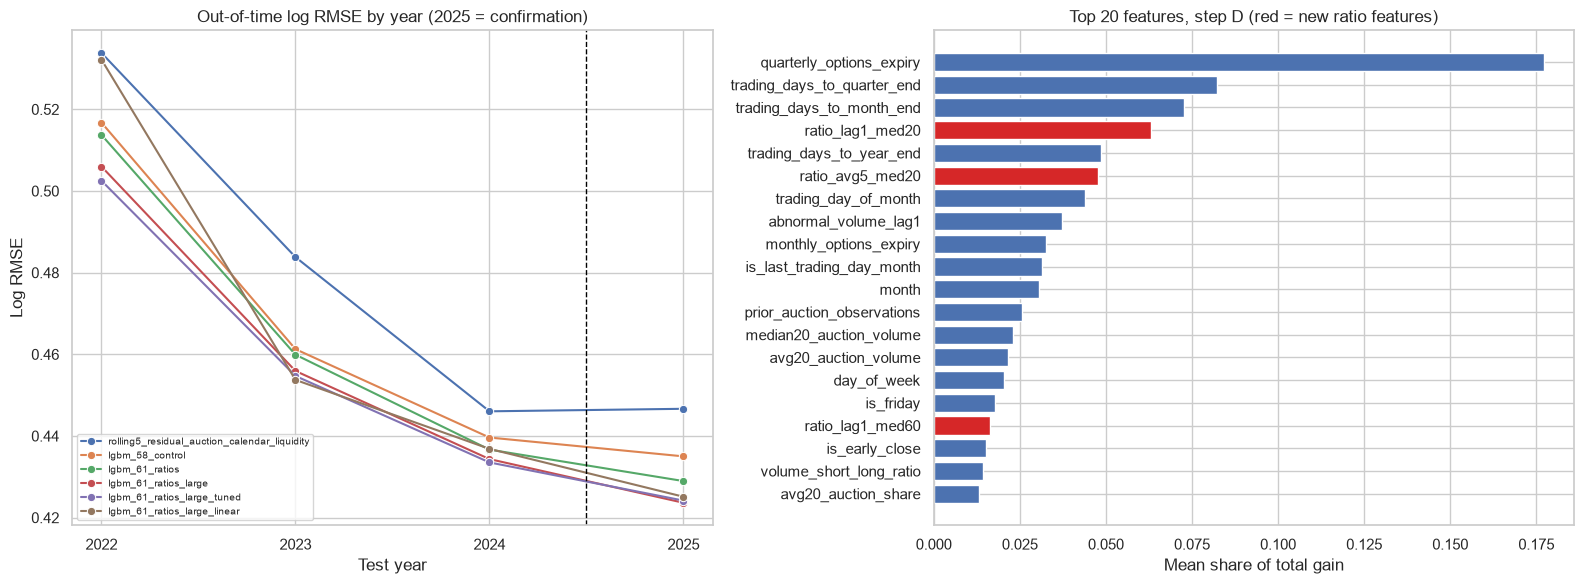

In [8]:
display(cu.segment_table(GLOB, ["frozen_prediction"] + NAMES).round(4))

top = (importance[importance.candidate == "lgbm_61_ratios_large_tuned"]
       .groupby("source_feature").gain_share.mean().sort_values(ascending=False).head(20))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot = metrics[metrics.candidate.isin([cu.CHAMPION] + NAMES)]
sns.lineplot(data=plot, x="test_year", y="rmse_log", hue="candidate", marker="o", ax=axes[0])
axes[0].axvline(2024.5, color="black", ls="--", lw=1)
axes[0].set_xticks(cu.TEST_YEARS)  # whole years only; otherwise matplotlib picks 0.5 steps
axes[0].set(title="Out-of-time log RMSE by year (2025 = confirmation)", xlabel="Test year", ylabel="Log RMSE")
axes[0].legend(fontsize=7)
colors = ["#d62728" if f in cu.RATIO_FEATURES else "#4c72b0" for f in top.index]
axes[1].barh(top.index[::-1], top.values[::-1], color=colors[::-1])
axes[1].set(title="Top 20 features, step D (red = new ratio features)", xlabel="Mean share of total gain")
plt.tight_layout()
plt.savefig(OUT / "lightgbm_improvements.png", bbox_inches="tight")
plt.show()

## Conclusion

In [9]:
best = vs_ridge[vs_ridge.candidate != cu.CHAMPION].sort_values("development_rmse_log").iloc[0]
summary = {
    "best_development_candidate": best.candidate,
    "best_development_rmse_log": float(best.development_rmse_log),
    "change_vs_frozen_ridge": float(best.rmse_change_vs_reference),
    "passes_gate_vs_frozen_ridge": vs_ridge.loc[vs_ridge.passes_gate == True, "candidate"].tolist(),
    "passes_gate_vs_lgbm_control": vs_control.loc[vs_control.passes_gate == True, "candidate"].tolist(),
    "smoke_mode": cu.SMOKE,
}
with open(OUT / "recommendation.json", "w") as handle:
    json.dump(summary, handle, indent=2)
display(summary)

{'best_development_candidate': 'lgbm_61_ratios_large_tuned',
 'best_development_rmse_log': 0.46357074256082437,
 'change_vs_frozen_ridge': -0.024309638505446207,
 'passes_gate_vs_frozen_ridge': ['lgbm_58_control',
  'lgbm_61_ratios',
  'lgbm_61_ratios_large',
  'lgbm_61_ratios_large_tuned'],
 'passes_gate_vs_lgbm_control': ['lgbm_61_ratios',
  'lgbm_61_ratios_large',
  'lgbm_61_ratios_large_tuned'],
 'smoke_mode': False}